# Amazon Category-Wise Sales Forecasting & Spike Detection

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot

df = pd.read_excel(r"/content/Amazon Sales Data India.xlsx")
df.describe()

,Quantity,Unit_Price_INR,Discount_Pct,Total_Sales_INR,Profit_INR
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2.492600,6821.399659,0.085575,15578.989389,3316.700849
std,1.110076,9183.501994,0.076172,24159.351687,5805.862200
min,1.000000,150.270000,0.000000,118.820000,0.000000
25%,2.000000,1002.822500,0.000000,1931.245000,299.325000
50%,2.000000,2290.080000,0.100000,4795.800000,891.625000
75%,3.000000,7628.625000,0.150000,17357.332500,3250.530000
max,4.000000,34992.800000,0.250000,139647.920000,45596.300000


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         10000 non-null  object 
 1   Order_Date       10000 non-null  object 
 2   Category         10000 non-null  object 
 3   Product          10000 non-null  object 
 4   Quantity         10000 non-null  int64  
 5   Unit_Price_INR   10000 non-null  float64
 6   Discount_Pct     10000 non-null  float64
 7   Total_Sales_INR  10000 non-null  float64
 8   Profit_INR       10000 non-null  float64
 9   Payment_Method   10000 non-null  object 
 10  Fulfillment      10000 non-null  object 
 11  Order_Status     10000 non-null  object 
 12  Ship_State       10000 non-null  object 
dtypes: float64(4), int64(1), object(8)
memory usage: 1015.8+ KB


# Datatype formatting

In [6]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"],errors = "coerce")


In [7]:
cat_cols = ["Category","Product","Payment_Method","Fulfillment","Order_Status","Ship_State"]

df[cat_cols] = df[cat_cols].astype("category")

In [8]:
df["Year"] = df["Order_Date"].dt.year
df["Month"] = df["Order_Date"].dt.month
df["Quarter"] = df["Order_Date"].dt.quarter


# Data Validation

In [9]:
print(df.isnull().sum())
print(df.duplicated().sum())


Order_ID           0
Order_Date         0
Category           0
Product            0
Quantity           0
Unit_Price_INR     0
Discount_Pct       0
Total_Sales_INR    0
Profit_INR         0
Payment_Method     0
Fulfillment        0
Order_Status       0
Ship_State         0
Year               0
Month              0
Quarter            0
dtype: int64
0


# Data Quality Checking

In [10]:
# Checking date range
print("Start date:", df["Order_Date"].min())
print("End date:",df["Order_Date"].max())

Start date: 2024-01-01 00:00:00
End date: 2026-08-30 00:00:00


In [11]:
# Checking of category distribution
df["Category"].value_counts()

,count
Category,
Electronics & Mobiles,3045
Apparel & Fashion,2580
Home & Kitchen,1888
Beauty & Personal Care,1499
Pantry & Groceries,988


In [12]:
# Check numerical columns
print("\nNumerical summary:")
print(df[[
    "Quantity",
    "Unit_Price_INR",
    "Discount_Pct",
    "Total_Sales_INR",
    "Profit_INR"
]].describe())


Numerical summary:
           Quantity  Unit_Price_INR  Discount_Pct  Total_Sales_INR  \
count  10000.000000    10000.000000  10000.000000     10000.000000   
mean       2.492600     6821.399659      0.085575     15578.989389   
std        1.110076     9183.501994      0.076172     24159.351687   
min        1.000000      150.270000      0.000000       118.820000   
25%        2.000000     1002.822500      0.000000      1931.245000   
50%        2.000000     2290.080000      0.100000      4795.800000   
75%        3.000000     7628.625000      0.150000     17357.332500   
max        4.000000    34992.800000      0.250000    139647.920000   

         Profit_INR  
count  10000.000000  
mean    3316.700849  
std     5805.862200  
min        0.000000  
25%      299.325000  
50%      891.625000  
75%     3250.530000  
max    45596.300000  


In [13]:
df["calculated_sales"] = df["Total_Sales_INR"] * (1 - df["Discount_Pct"])


In [14]:
df.head()

,Order_ID,Order_Date,Category,Product,Quantity,Unit_Price_INR,Discount_Pct,Total_Sales_INR,Profit_INR,Payment_Method,Fulfillment,Order_Status,Ship_State,Year,Month,Quarter,calculated_sales
0,IN-AMD-100000,2024-04-12,Apparel & Fashion,Saree with Unstitched Blouse,3,1129.14,0.25,2540.56,702.96,Cash on Delivery (COD),Seller Flex,Delivered,Telangana,2024,4,2,1905.4200
1,IN-AMD-100001,2025-03-11,Apparel & Fashion,Men Denim Jeans,3,1159.01,0.05,3303.18,770.96,UPI,Amazon (FBA),Shipped,Kerala,2025,3,1,3138.0210
2,IN-AMD-100002,2026-05-10,Beauty & Personal Care,Ubtan Face Wash,1,287.77,0.00,287.77,86.73,UPI,Amazon (FBA),Delivered,West Bengal,2026,5,2,287.7700
3,IN-AMD-100003,2024-09-27,Electronics & Mobiles,Wireless Earbuds,4,20928.14,0.05,79526.93,26466.63,Credit/Debit Card,Amazon (FBA),Shipped,Rajasthan,2024,9,3,75550.5835
4,IN-AMD-100004,2024-04-16,Beauty & Personal Care,Sunscreen Gel SPF 50,1,931.65,0.15,791.90,217.90,UPI,Seller Flex,Delivered,Karnataka,2024,4,2,673.1150


In [15]:
# Calculate profit margin on net sales
df["Profit_Margin"] = (df["Profit_INR"] /df["Total_Sales_INR"].replace(0, np.nan)) * 100

# Business EDA

In [16]:
category_summary = df.groupby("Category").agg({"Quantity":"sum","Total_Sales_INR":"sum","Profit_INR":"sum","Profit_Margin":"mean","Order_ID":"nunique"}).sort_values(by ="Total_Sales_INR", ascending=False)
category_summary = category_summary.reset_index()
category_summary = category_summary.round(2)
category_summary.index = category_summary.index + 1
category_summary.head()

/tmp/ipykernel_4473/4048723351.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  category_summary = df.groupby("Category").agg({"Quantity":"sum","Total_Sales_INR":"sum","Profit_INR":"sum","Profit_Margin":"mean","Order_ID":"nunique"}).sort_values(by ="Total_Sales_INR", ascending=False)


,Category,Quantity,Total_Sales_INR,Profit_INR,Profit_Margin,Order_ID
1,Electronics & Mobiles,7579,1.235695e+08,26310257.24,21.34,3045
2,Home & Kitchen,4684,1.797322e+07,3837268.36,21.35,1888
3,Apparel & Fashion,6452,9.831025e+06,2085354.00,21.23,2580
4,Beauty & Personal Care,3734,2.889178e+06,604390.41,20.82,1499
5,Pantry & Groceries,2477,1.526964e+06,329738.48,21.50,988


# Electronics & Mobiles , Home & Kitchen	 Key drivers of sales

In [17]:
monthly_sales = df.pivot_table(
    index=pd.Grouper(key="Order_Date", freq="ME"),
    columns="Category",
    values="Total_Sales_INR",
    aggfunc="sum",
    observed=True,
    fill_value=0)

print(monthly_sales.head(15))

Category    Apparel & Fashion  Beauty & Personal Care  Electronics & Mobiles  \
Order_Date                                                                     
2024-01-31          310976.44                89137.83             3400559.44   
2024-02-29          279601.88                95679.66             3257861.87   
2024-03-31          317516.36                78392.14             4838193.16   
2024-04-30          291182.53                89172.34             3683969.05   
2024-05-31          345560.61               106655.40             3623884.09   
2024-06-30          321965.21                89148.47             3733266.13   
2024-07-31          282430.10               102088.93             4678954.19   
2024-08-31          307105.10                89010.08             3624826.61   
2024-09-30          301896.29                86635.63             3127757.19   
2024-10-31          290449.21                77022.99             3887417.34   
2024-11-30          316861.38           

In [18]:
monthly_demand = df.pivot_table(
    index=pd.Grouper(key="Order_Date", freq="ME"),
    columns="Category",
    values="Quantity",
    aggfunc="sum",
    observed=True,
    fill_value=0)

print(monthly_demand.head(12))

Category    Apparel & Fashion  Beauty & Personal Care  Electronics & Mobiles  \
Order_Date                                                                     
2024-01-31                203                     121                    219   
2024-02-29                177                     128                    187   
2024-03-31                209                      90                    272   
2024-04-30                203                     111                    248   
2024-05-31                220                     139                    244   
2024-06-30                206                     119                    242   
2024-07-31                178                     130                    273   
2024-08-31                215                     121                    217   
2024-09-30                209                     119                    200   
2024-10-31                183                     102                    254   
2024-11-30                196           

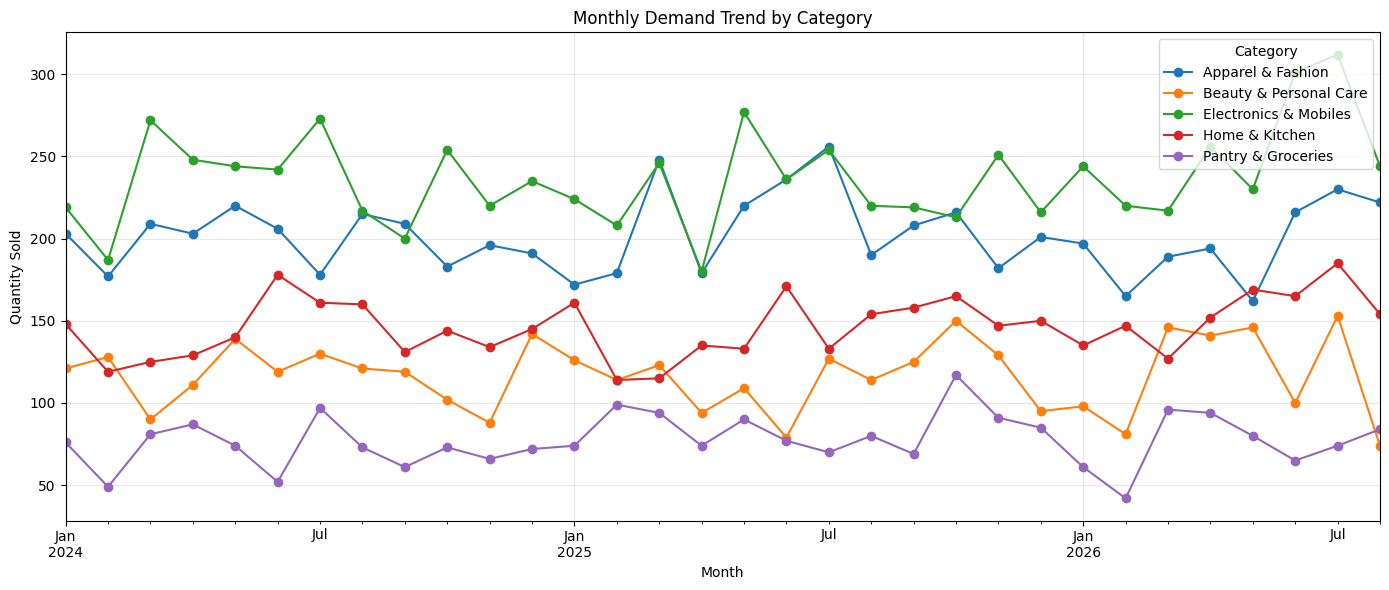

In [19]:
import matplotlib.pyplot as plt

monthly_demand.plot(
    figsize=(14, 6),
    marker="o")

plt.title("Monthly Demand Trend by Category")
plt.xlabel("Month")
plt.ylabel("Quantity Sold")
plt.legend(title="Category")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# My recommendations as a business consultant
I would present these five recommendations to management:
1. Electronics: Make this the priority category for inventory planning because it consistently has the highest unit demand.
2. Apparel: Investigate the July 2025 peak and build a more responsive seasonal inventory plan if the pattern is confirmed.
3. Home & Kitchen: Maintain balanced inventory and investigate occasional demand increases before increasing stock.
4. Beauty: Review promotional performance and consider more frequent replenishment.
5. Pantry: Investigate the sharp decline in February 2026 before making inventory reduction decisions.
5. One important limitation
We cannot confidently call every peak a seasonal spike.

For example, Electronics has high demand in July 2026, but we need to compare it with July 2024 and July 2025. If similar increases occur repeatedly, seasonality becomes more plausible. If not, it may be an unusual event.

Also, this chart displays quantity, not stock availability or actual customer demand. We need to examine order status before interpreting the figures as fulfilled sales.

# Trend analysis using a 3-month moving average

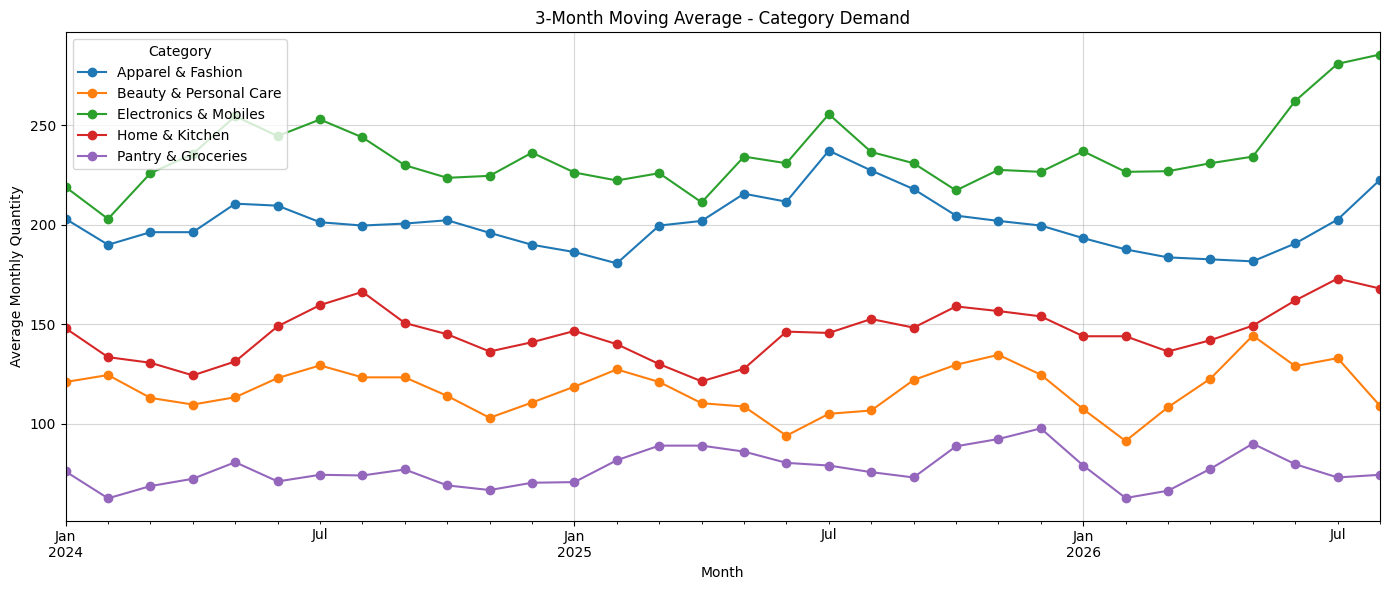

In [20]:
monthly_trend = monthly_demand.rolling(3,min_periods=1).mean()

monthly_trend.plot(figsize=(14, 6),marker="o")

plt.title("3-Month Moving Average - Category Demand")
plt.xlabel("Month")
plt.ylabel("Average Monthly Quantity")
plt.grid(alpha=0.5)
plt.tight_layout()
plt.show()

# 1. Category-wise interpretation
1. Electronics & Mobiles
Strongest demand and recent growth
- The moving average starts around 225 units in early 2024.
- It declines towards approximately 210–225 during parts of 2025.
- From early 2026, it rises considerably, reaching approximately 285 units in August 2026.
Management decision: Prioritize procurement planning and supplier capacity. Investigate the recent growth to determine whether it is supported by sustained customer demand or a temporary sales campaign.


2. Apparel & Fashion
Recent recovery
- Demand stays around 195–210 units during much of 2024.
- It rises around July 2025 to approximately 237 units.
- It declines through early 2026, reaching approximately 181 units.
- It then recovers to approximately 223 units by August 2026.
Management decision: Increase replenishment cautiously while monitoring whether the recovery continues. Avoid basing purchases on one strong month.


3. Home & Kitchen
Relatively stable demand
- It fluctuates mostly between 120 and 170 units.
- It reaches a local high around August 2024.
- After a weaker period in early 2025, it recovers during the second half of 2025.
- It finishes around 168 units in August 2026.
Management decision: Maintain balanced stock levels and use historical demand to set replenishment thresholds.


4. Beauty & Personal Care
Volatile demand
- It fluctuates approximately between 90 and 145 units.
- It has a noticeable increase during late 2025.
- It declines in early 2026 and recovers around May–June.
- It ends near 110 units in August 2026.
Management decision: Monitor campaign performance, product mix and repeat purchases. Use flexible inventory allocation rather than assuming continuous growth.


5. Pantry & Groceries
Lowest demand and recent weakness
- It remains mostly between 65 and 90 units.
- It reaches approximately 98 units around December 2025.
- It falls to around 62 units in February 2026.
- It recovers slightly but ends around 74 units.
Management decision: Investigate the February decline and maintain disciplined inventory. Check cancellations, stockouts and product availability before reducing stock.

In [21]:
electronics = monthly_demand["Electronics & Mobiles"]

electronics_analysis = pd.DataFrame({
    "Actual_Demand": electronics})

electronics_analysis["Rolling_Mean"] = (
    electronics.rolling(window=3,min_periods=1).mean())

electronics_analysis["Rolling_Std"] = (
    electronics.rolling(window=3,min_periods=1).std())

electronics_analysis["Upper_Limit"] = (
    electronics_analysis["Rolling_Mean"] +
    2 * electronics_analysis["Rolling_Std"])

electronics_analysis["Lower_Limit"] = (
    electronics_analysis["Rolling_Mean"] -
    2 * electronics_analysis["Rolling_Std"])

print(electronics_analysis.tail(12).round(2))

            Actual_Demand  Rolling_Mean  Rolling_Std  Upper_Limit  Lower_Limit
Order_Date                                                                    
2025-09-30            219        231.00        19.92       270.85       191.15
2025-10-31            213        217.33         3.79       224.91       209.76
2025-11-30            251        227.67        20.43       268.52       186.81
2025-12-31            216        226.67        21.13       268.92       184.41
2026-01-31            244        237.00        18.52       274.04       199.96
2026-02-28            220        226.67        15.14       256.95       196.38
2026-03-31            217        227.00        14.80       256.60       197.40
2026-04-30            256        231.00        21.70       274.41       187.59
2026-05-31            230        234.33        19.86       274.05       194.62
2026-06-30            301        262.33        35.92       334.18       190.49
2026-07-31            312        281.00        44.51

In [22]:
electronics_analysis["Spike_Status"] = "Normal"

electronics_analysis.loc[
    electronics_analysis["Actual_Demand"] >
    electronics_analysis["Upper_Limit"],
    "Spike_Status"] = "High Demand"

electronics_analysis.loc[
    electronics_analysis["Actual_Demand"] <
    electronics_analysis["Lower_Limit"],
    "Spike_Status"] = "Low Demand"

print(electronics_analysis.round(2).tail(15))

            Actual_Demand  Rolling_Mean  Rolling_Std  Upper_Limit  \
Order_Date                                                          
2025-06-30            236        231.00        48.69       328.39   
2025-07-31            254        255.67        20.55       296.77   
2025-08-31            220        236.67        17.01       270.69   
2025-09-30            219        231.00        19.92       270.85   
2025-10-31            213        217.33         3.79       224.91   
2025-11-30            251        227.67        20.43       268.52   
2025-12-31            216        226.67        21.13       268.92   
2026-01-31            244        237.00        18.52       274.04   
2026-02-28            220        226.67        15.14       256.95   
2026-03-31            217        227.00        14.80       256.60   
2026-04-30            256        231.00        21.70       274.41   
2026-05-31            230        234.33        19.86       274.05   
2026-06-30            301        2

In [23]:
print(electronics_analysis.loc[
    electronics_analysis["Spike_Status"] == "High Demand",
    "Actual_Demand"
])

Series([], Freq: ME, Name: Actual_Demand, dtype: int64)


In [24]:
electronics_analysis

,Actual_Demand,Rolling_Mean,Rolling_Std,Upper_Limit,Lower_Limit,Spike_Status
Order_Date,,,,,,
2024-01-31,219,219.000000,NaN,NaN,NaN,Normal
2024-02-29,187,203.000000,22.627417,248.254834,157.745166,Normal
2024-03-31,272,226.000000,42.930176,311.860352,140.139648,Normal
2024-04-30,248,235.666667,43.821608,323.309883,148.023451,Normal
2024-05-31,244,254.666667,15.143756,284.954178,224.379155,Normal
2024-06-30,242,244.666667,3.055050,250.776768,238.556566,Normal
2024-07-31,273,253.000000,17.349352,287.698703,218.301297,Normal
2024-08-31,217,244.000000,28.053520,300.107041,187.892959,Normal
2024-09-30,200,230.000000,38.196859,306.393717,153.606283,Normal


# Overall Sales Time Series Decomposition (Trend, Seasonality & Residuals)

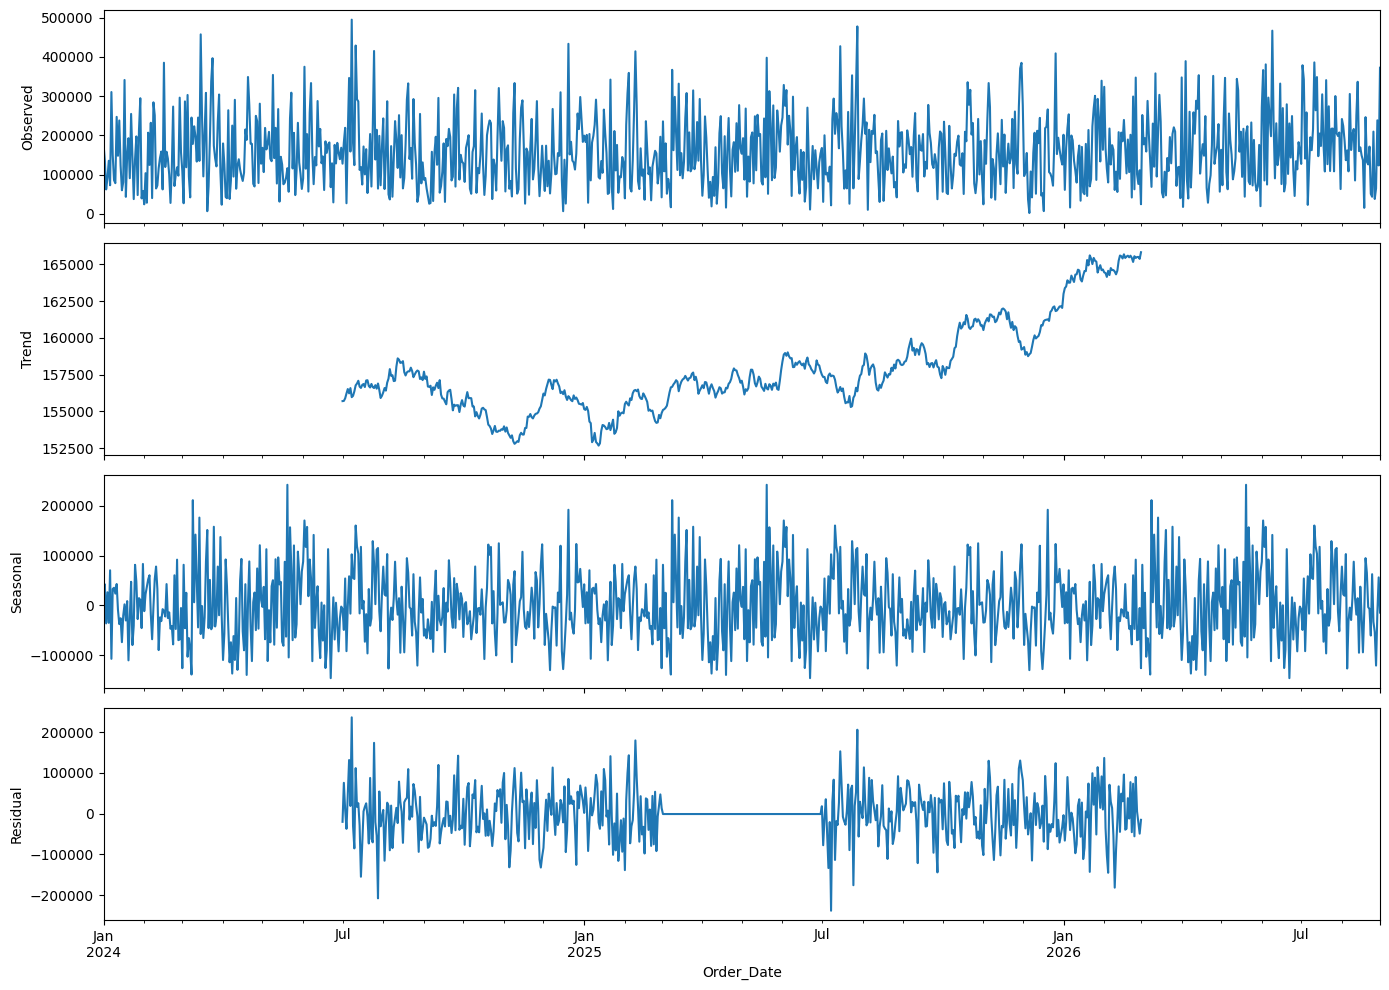

In [24]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose


daily_total = df.groupby('Order_Date')['Total_Sales_INR'].sum().resample('D').sum().fillna(0)


decomposition = seasonal_decompose(daily_total, model='additive', period=365)


fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(14, 10), sharex=True)
decomposition.observed.plot(ax=ax1)
ax1.set_ylabel('Observed')
decomposition.trend.plot(ax=ax2)
ax2.set_ylabel('Trend')
decomposition.seasonal.plot(ax=ax3)
ax3.set_ylabel('Seasonal')
decomposition.resid.plot(ax=ax4)
ax4.set_ylabel('Residual')

plt.tight_layout()
plt.show()

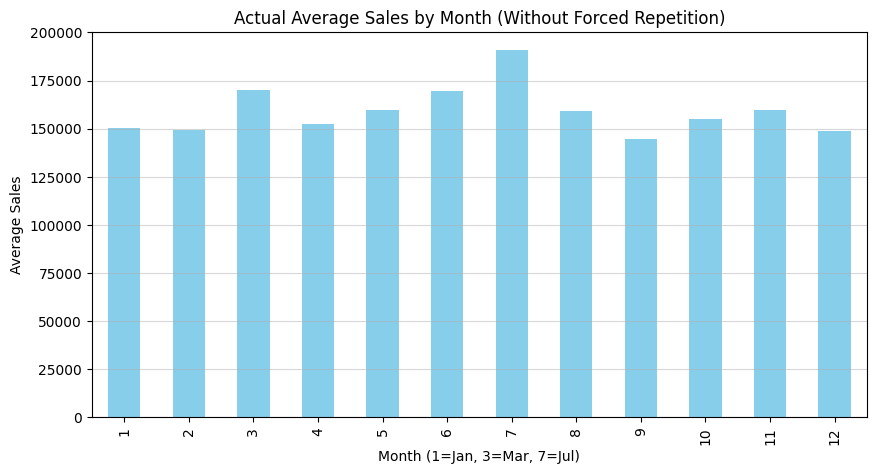

In [26]:
monthly_avg = daily_total.groupby(daily_total.index.month).mean()
monthly_avg.plot(kind='bar', figsize=(10, 5), color='skyblue')
plt.title("Actual Average Sales by Month (Without Forced Repetition)")
plt.xlabel("Month (1=Jan, 3=Mar, 7=Jul)")
plt.ylabel("Average Sales")
plt.grid(axis='y', alpha=0.5)
plt.show()

Financial Year-End Closings (March): In India, March marks the end of the financial year. Corporate budgets, tax-saving purchases, and institutional spending peak as businesses rush to clear or utilize allocated funds before the fiscal deadline.

Academic and Institutional Cycles (June): June is the universal start of the academic year across schools and colleges in India. This triggers heavy, high-volume purchases of laptops, tablets, stationery, and backpacks.

Mid-Year E-Commerce Megasales (July): Major online retail platforms (such as Amazon and Flipkart) routinely host massive mid-year promotional campaigns—most notably Amazon Prime Day—in July. These heavily marketed discount events artificially drive up transaction volumes and create industry-wide demand spikes.

Baseline Stability in Other Months: Outside of these distinct fiscal, academic, and promotional windows, consumer demand returns to predictable, steady baseline levels governed by daily utility needs rather than seasonal catalysts.

Inventory Planning Implications: Recognizing these exact external drivers means supply chain teams can pre-position stock in February (for March) and May (for June–July) to prevent stockouts.

Marketing Budget Allocation: Digital marketing expenditure should be scaled up dynamically ahead of these known windows rather than spread evenly throughout the year.

Long-Term Trend Adaptation: Factoring these recurring external shocks into forecasting models (like ARIMA or Prophet) prevents normal seasonal surges from being misidentified as random anomalies.

In [ ]:

from pmdarima import auto_arima

# Fit auto_arima with seasonal component m=12 (since your peaks are yearly in Month 3 and 7)
stepwise_model = auto_arima(df['calculated_sales'],
                            start_p=1, start_q=1,
                            max_p=3, max_q=3,
                            m=12,              # 12 months seasonal cycle
                            start_P=0,
                            seasonal=True,     # Turn on seasonality for March/July peaks
                            d=None,            # Let model determine d
                            D=1,               # Seasonal differencing
                            trace=True,
                            error_action='ignore',
                            suppress_warnings=True,
                            stepwise=True)

print(stepwise_model.summary())

Performing stepwise search to minimize aic
 ARIMA(1,0,1)(0,1,1)[12] intercept   : AIC=inf, Time=23.66 sec
 ARIMA(0,0,0)(0,1,0)[12] intercept   : AIC=235567.936, Time=0.58 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : AIC=233081.376, Time=7.32 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : AIC=inf, Time=77.62 sec
 ARIMA(0,0,0)(0,1,0)[12]             : AIC=235565.943, Time=0.46 sec
 ARIMA(1,0,0)(0,1,0)[12] intercept   : AIC=235566.124, Time=0.72 sec
 ARIMA(1,0,0)(2,1,0)[12] intercept   : AIC=232228.887, Time=14.51 sec
 ARIMA(1,0,0)(2,1,1)[12] intercept   : AIC=inf, Time=98.40 sec
 ARIMA(1,0,0)(1,1,1)[12] intercept   : AIC=inf, Time=45.65 sec
 ARIMA(0,0,0)(2,1,0)[12] intercept   : AIC=232230.338, Time=11.93 sec
 ARIMA(2,0,0)(2,1,0)[12] intercept   : AIC=232230.305, Time=20.25 sec


In [26]:
df_indexed = df.set_index('Order_Date')

# 2. Aggregate the total sales by Month Start ('MS')
monthly_total = df_indexed['Total_Sales_INR'].resample('MS').sum().fillna(0)

# 3. Preview the aggregated monthly data
print(monthly_total.head())

Order_Date
2024-01-01    4441265.57
2024-02-01    4071073.66
2024-03-01    5761054.84
2024-04-01    4612546.48
2024-05-01    4660178.05
Freq: MS, Name: Total_Sales_INR, dtype: float64


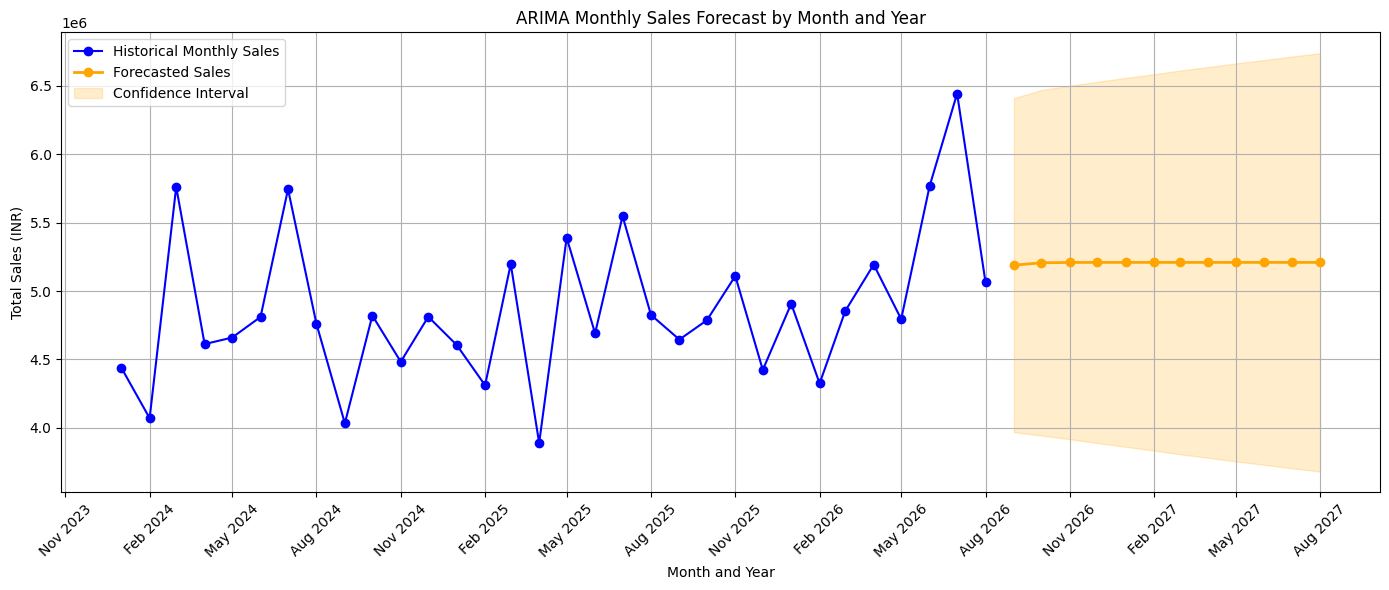

In [50]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.arima.model import ARIMA

# Fit the standard ARIMA model (no seasonal_order)
model = ARIMA(monthly_total,
              order=(1, 1, 1),
              enforce_stationarity=False,
              enforce_invertibility=False)

results = model.fit()

# Forecast the next 12 months
forecast_steps = 12
forecast = results.get_forecast(steps=forecast_steps)
forecast_mean = forecast.predicted_mean
conf_int = forecast.conf_int()

# Visualization
plt.figure(figsize=(14, 6))

plt.plot(monthly_total.index, monthly_total, label='Historical Monthly Sales', color='blue', marker='o')
plt.plot(forecast_mean.index, forecast_mean, label='Forecasted Sales', color='orange', marker='o', linewidth=2)
plt.fill_between(conf_int.index,
                 conf_int.iloc[:, 0],
                 conf_int.iloc[:, 1],
                 color='orange', alpha=0.2, label='Confidence Interval')

ax = plt.gca()
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))

plt.title('ARIMA Monthly Sales Forecast by Month and Year')
plt.xlabel('Month and Year')
plt.ylabel('Total Sales (INR)')
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [40]:
# Convert the summary directly to a string first, then print it
print(str(test_results.summary()))

                                     SARIMAX Results                                      
Dep. Variable:                                  y   No. Observations:                   36
Model:             SARIMAX(1, 0, 0)x(1, 0, 0, 12)   Log Likelihood                 -52.085
Date:                            Thu, 12 Nov 2026   AIC                            110.170
Time:                                    18:05:37   BIC                            114.920
Sample:                                         0   HQIC                           111.828
                                             - 36                                         
Covariance Type:                              opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.9954      0.003    294.829      0.000       0.989       1.002
ar.S.L12       0.9998    7.6e-05   

# Categorywise Sale Forcasting

In [43]:
category_forecasts = {}

for category in df['Category'].unique():

    cat_df = df[df['Category'] == category]


    monthly_cat_sales = cat_df.resample('M', on='Order_Date')['calculated_sales'].sum()


    print(f"Processing for category: {category}, Total months: {len(monthly_cat_sales)}")

Processing for category: Apparel & Fashion, Total months: 32
Processing for category: Beauty & Personal Care, Total months: 32
Processing for category: Electronics & Mobiles, Total months: 32
Processing for category: Home & Kitchen, Total months: 32
Processing for category: Pantry & Groceries, Total months: 32


/tmp/ipykernel_4473/385000508.py:8: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_cat_sales = cat_df.resample('M', on='Order_Date')['calculated_sales'].sum()


In [48]:
import pandas as pd
from statsmodels.tsa.arima.model import ARIMA

# 1. Assuming your main DataFrame is named 'df'
# Make sure your date column is in datetime format
df['Order_Date'] = pd.to_datetime(df['Order_Date'])

# Dictionary to store results and forecasts for each category
category_forecasts = {}

# 2. Loop through each unique category in your dataset
for category in df['Category'].unique():
    print(f"\n--- Processing Category: {category} ---")

    # Filter data for the current category
    cat_df = df[df['Category'] == category].copy()

    # Set Order_Date as index and resample to monthly total sales ('ME' or 'M' depending on pandas version)
    monthly_sales = cat_df.set_index('Order_Date')['calculated_sales'].resample('ME').sum()

    # Drop any missing values if a month had zero transactions
    monthly_sales = monthly_sales.dropna()

    # Check if there is enough data to fit a model (e.g., at least 12 months)
    if len(monthly_sales) < 12:
        print(f"Skipping {category}: Not enough data points ({len(monthly_sales)} months found).")
        continue

    try:
        # 3. Fit a standard ARIMA model (using order=(1,1,1) as a flexible baseline for fluctuating data)
        model = ARIMA(monthly_sales, order=(1, 1, 1))
        results = model.fit()

        # 4. Forecast the next 12 months
        forecast_steps = 12
        forecast = results.get_forecast(steps=forecast_steps)
        forecast_mean = forecast.predicted_mean
        conf_int = forecast.conf_int()

        # Save results in our dictionary for later use (like plotting)
        category_forecasts[category] = {
            'model_results': results,
            'forecast_values': forecast_mean,
            'confidence_interval': conf_int
        }

        # Print a quick snapshot of the 12-month forecast for this category
        print(f"Successfully forecasted next {forecast_steps} months for {category}:")
        print(forecast_mean.head(3)) # Displaying first 3 months of forecast

    except Exception as e:
        print(f"Error modeling category {category}: {e}")

print("\nAll category-wise forecasts completed!")


--- Processing Category: Apparel & Fashion ---
Successfully forecasted next 12 months for Apparel & Fashion:
2026-09-30    314110.466763
2026-10-31    313950.083367
2026-11-30    313933.317374
Freq: ME, Name: predicted_mean, dtype: float64

--- Processing Category: Beauty & Personal Care ---
Successfully forecasted next 12 months for Beauty & Personal Care:
2026-09-30    77576.210402
2026-10-31    80912.198294
2026-11-30    81481.051927
Freq: ME, Name: predicted_mean, dtype: float64

--- Processing Category: Electronics & Mobiles ---
Successfully forecasted next 12 months for Electronics & Mobiles:
2026-09-30    3.989848e+06
2026-10-31    3.777818e+06
2026-11-30    3.915919e+06
Freq: ME, Name: predicted_mean, dtype: float64

--- Processing Category: Home & Kitchen ---
Successfully forecasted next 12 months for Home & Kitchen:
2026-09-30    605938.313318
2026-10-31    601054.240559
2026-11-30    602085.384012
Freq: ME, Name: predicted_mean, dtype: float64

--- Processing Category: Pant

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params


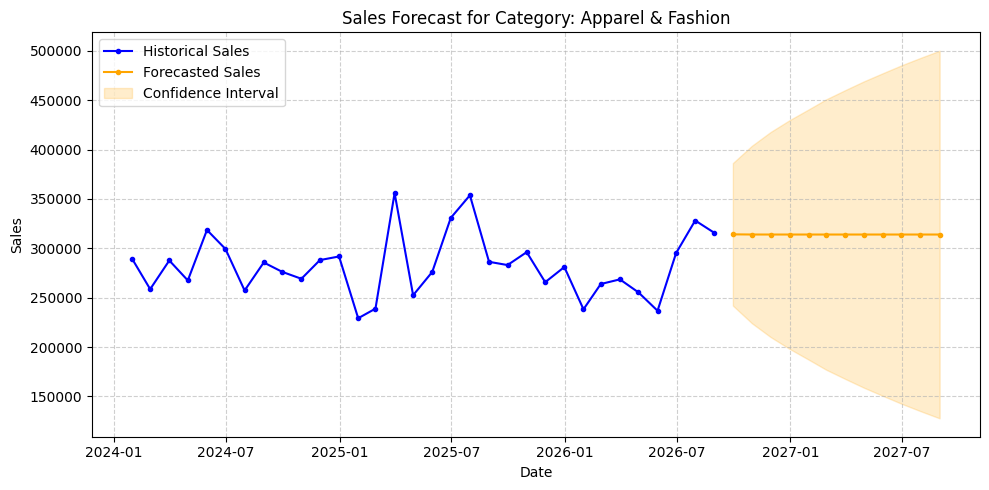

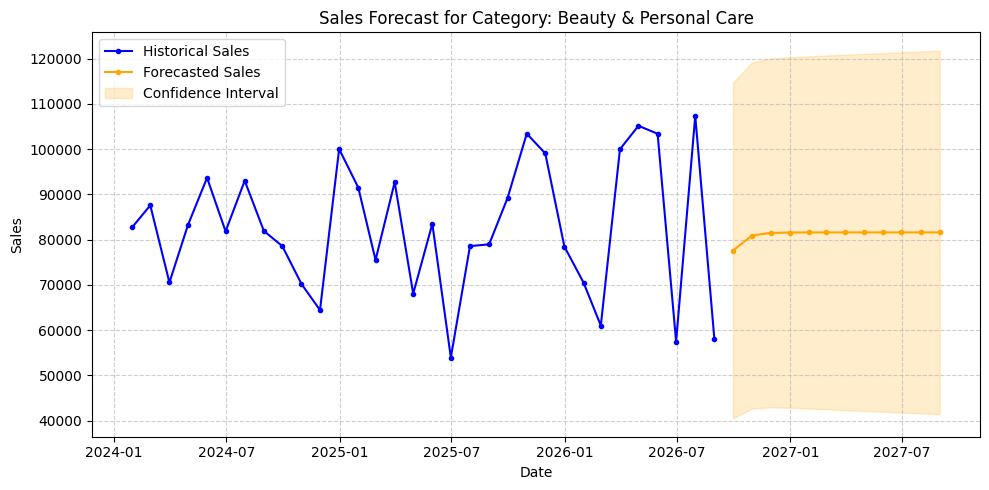

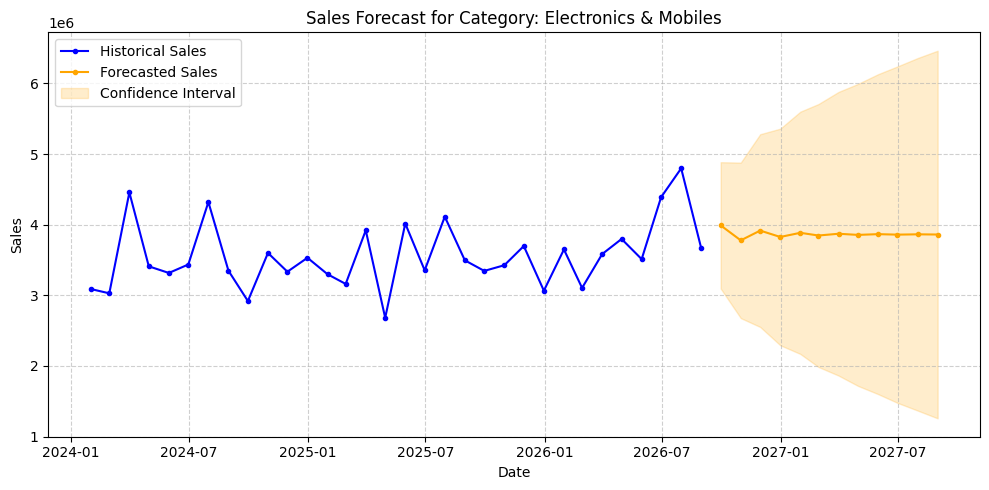

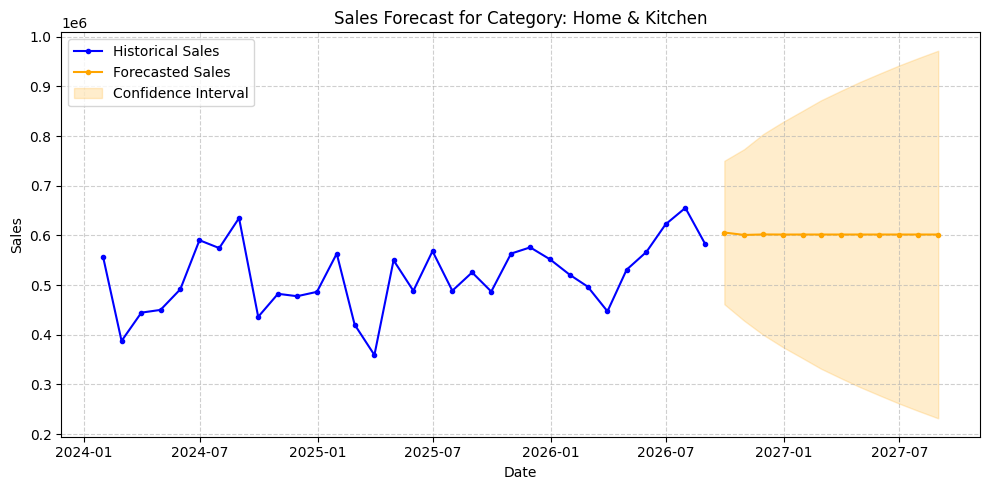

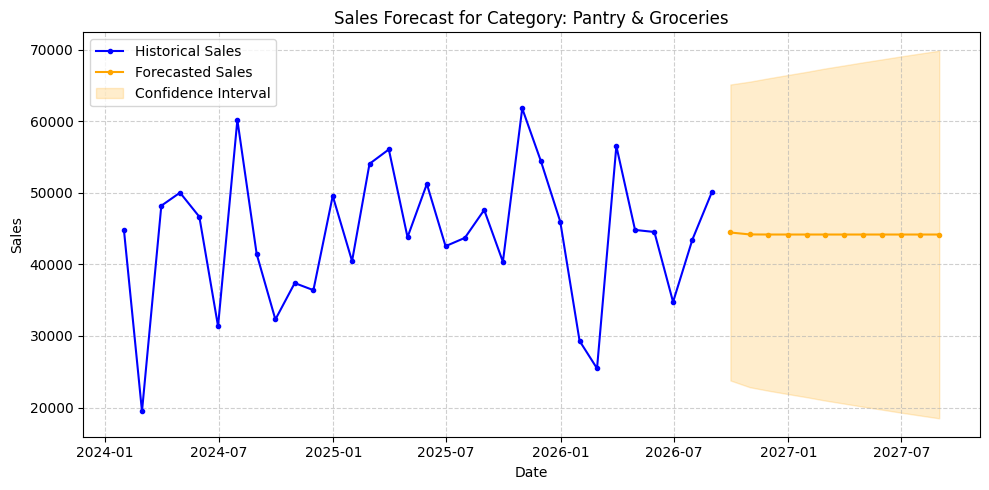

In [49]:
import matplotlib.pyplot as plt

# Make sure you have already run the previous forecasting loop so 'category_forecasts' exists
for category, data in category_forecasts.items():
    results = data['model_results']
    forecast_mean = data['forecast_values']
    conf_int = data['confidence_interval']

    # Get the original historical data used in the model
    history = results.data.endog
    history_index = results.data.dates # Or your date index if set properly

    plt.figure(figsize=(10, 5))

    # Plot historical sales
    plt.plot(history_index, history, label='Historical Sales', color='blue', marker='o', markersize=3)

    # Plot forecasted sales
    plt.plot(forecast_mean.index, forecast_mean, label='Forecasted Sales', color='orange', marker='o', markersize=3)

    # Shade the confidence interval
    plt.fill_between(
        conf_int.index,
        conf_int.iloc[:, 0],
        conf_int.iloc[:, 1],
        color='orange',
        alpha=0.2,
        label='Confidence Interval'
    )

    plt.title(f'Sales Forecast for Category: {category}')
    plt.xlabel('Date')
    plt.ylabel('Sales')
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()

    # Display each category's chart one by one
    plt.show()